# NeumonAI – Fase 2: Solución con CNN (Redes Neuronales)


In [ ]:
# 0. Librerías y configuración global
import os, re, glob, hashlib, itertools, time, shutil, warnings, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, classification_report)
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')

SEED, IMG, BATCH = 42, 150, 32
EPOCHS = 3      # restricción del proyecto (súbelo a 10 si el tiempo lo permite)
N_REPS = 3      # repeticiones por configuración
os.makedirs('evidencias', exist_ok=True)

def guardar(nombre):
    plt.savefig(f'evidencias/{nombre}.png', dpi=150, bbox_inches='tight'); plt.show()

print('GPU:', tf.config.list_physical_devices('GPU') or 'NO DETECTADA (será lento)')

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Punto 4 – Modelo de datos
## A.1 Descarga del dataset



In [ ]:
!pip install -q kaggle
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/ 2>/dev/null || true
!chmod 600 ~/.kaggle/kaggle.json 2>/dev/null || true
import os
if not os.path.exists('chest_xray_pneumonia'):
    !kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
    !unzip -o -q chest-xray-pneumonia.zip -d chest_xray_pneumonia
print('Dataset listo.')

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:59<00:00, 41.4MB/s]

Dataset listo.


## A.2 Inventario original
Contamos imágenes por partición y clase.

clase,NORMAL,PNEUMONIA,All,% neumonía
split,,,,
test,234,390,624,62.5
train,1341,3875,5216,74.3
val,8,8,16,50.0
All,1583,4273,5856,73.0


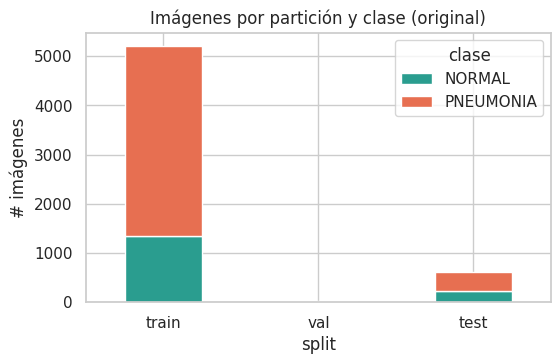

In [ ]:
BASE = 'chest_xray_pneumonia/chest_xray'
rows = [dict(path=p, split=s, clase=c)
        for s in ['train','val','test'] for c in ['NORMAL','PNEUMONIA']
        for p in glob.glob(f'{BASE}/{s}/{c}/*.jp*g')]
df = pd.DataFrame(rows); df['y'] = (df.clase == 'PNEUMONIA').astype(int)

tabla_orig = pd.crosstab(df.split, df.clase, margins=True)
tabla_orig['% neumonía'] = (100 * tabla_orig.PNEUMONIA / tabla_orig.All).round(1)
display(tabla_orig)
tabla_orig.to_csv('evidencias/tabla_inventario_original.csv')

pd.crosstab(df.split, df.clase).loc[['train','val','test']].plot(kind='bar', stacked=True, figsize=(6,3.5), color=['#2a9d8f','#e76f51'])
plt.title('Imágenes por partición y clase (original)'); plt.xticks(rotation=0); plt.ylabel('# imágenes')
guardar('A2_inventario_original')

## A.3 Muestras y calidad de los archivos
Revisamos: archivos corruptos, tamaños, canales y duplicados exactos.

  0%|          | 0/5856 [00:00<?, ?it/s]

Archivos corruptos: 0
Modos de color: {'L': 5573, 'RGB': 283}
Duplicados exactos: 32


w                                                        \
            count    mean    std    min     25%     50%     75%     max   
clase                                                                     
NORMAL     1583.0  1686.0  305.0  912.0  1472.0  1654.0  1848.0  2916.0   
PNEUMONIA  4273.0  1195.0  285.0  384.0  1000.0  1160.0  1360.0  2772.0   

                h                                                        
            count    mean    std    min     25%     50%     75%     max  
clase                                                                    
NORMAL     1583.0  1379.0  343.0  496.0  1140.0  1323.0  1554.0  2713.0  
PNEUMONIA  4273.0   820.0  271.0  127.0   640.0   776.0   960.0  2304.0

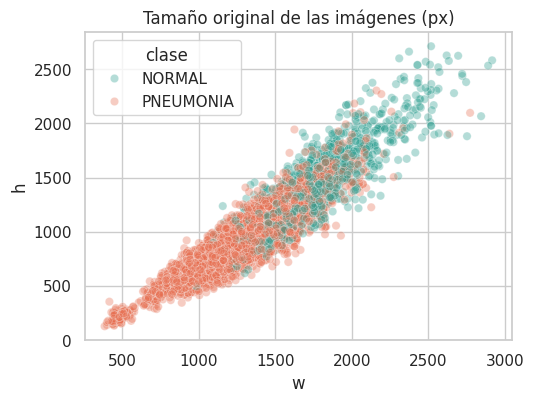

In [ ]:
def info(p):
    try:
        with Image.open(p) as im:
            w, h, modo = im.size[0], im.size[1], im.mode
            im.verify()
        return w, h, modo, hashlib.md5(open(p,'rb').read()).hexdigest(), True
    except Exception:
        return None, None, None, None, False

with ThreadPoolExecutor(8) as ex: out = list(tqdm(ex.map(info, df.path), total=len(df)))
df[['w','h','modo','md5','ok']] = pd.DataFrame(out, index=df.index)

print('Archivos corruptos:', (df.ok == False).sum())
print('Modos de color:', df.modo.value_counts().to_dict())
print('Duplicados exactos:', df.md5.duplicated().sum())
display(df.groupby('clase')[['w','h']].describe().round(0))

plt.figure(figsize=(5.5,4))
sns.scatterplot(data=df, x='w', y='h', hue='clase', alpha=.35, palette=['#2a9d8f','#e76f51'])
plt.title('Tamaño original de las imágenes (px)'); guardar('A3_tamanos')

## A.4 Limpieza
1. Eliminar archivos corruptos.
2. Eliminar imágenes de train/val cuyo contenido **también está en test** (fuga de datos).
3. Eliminar duplicados exactos restantes.

In [ ]:
n0 = len(df)
df = df[df.ok == True]
n_corr = n0 - len(df)
test_hashes = set(df[df.split=='test'].md5)
mask_fuga = (df.split != 'test') & df.md5.isin(test_hashes)
n_fuga = mask_fuga.sum(); df = df[~mask_fuga]
n_dup = df.md5.duplicated().sum(); df = df.drop_duplicates('md5').reset_index(drop=True)

limpieza = pd.DataFrame({'Paso': ['Corruptos','Fuga train/val→test','Duplicados exactos','Imágenes finales'],
                         'Imágenes': [n_corr, n_fuga, n_dup, len(df)]})
display(limpieza); limpieza.to_csv('evidencias/tabla_limpieza.csv', index=False)

,Paso,Imágenes
0,Corruptos,0
1,Fuga train/val→test,0
2,Duplicados exactos,32
3,Imágenes finales,5824


## A.5 Nueva partición train / val / test
- **Test** se deja intacto (624 imágenes originales)
- Se **junta train + val** y se re-divide 80/20.

clase,NORMAL,PNEUMONIA,All,% neumonía
particion,,,,
train,1068,3100,4168,74.4
val,280,758,1038,73.0
test,231,387,618,62.6
All,1579,4245,5824,72.9


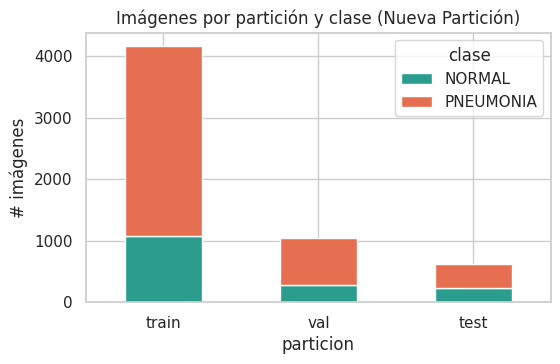

In [ ]:
def grupo(r):
    n = os.path.basename(r.path)
    m = re.search(r'person(\d+)', n) or re.search(r'IM-(\d+)', n)
    return f'{r.clase}_{m.group(1)}' if m else n
df['grupo'] = df.apply(grupo, axis=1)

dev = df[df.split != 'test'].reset_index(drop=True)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(dev, dev.y, groups=dev.grupo))
dev['particion'] = 'train'; dev.loc[va_idx, 'particion'] = 'val'
te = df[df.split == 'test'].copy(); te['particion'] = 'test'
data = pd.concat([dev, te]).reset_index(drop=True)

assert set(dev[dev.particion=='train'].grupo).isdisjoint(dev[dev.particion=='val'].grupo)
tabla_final = pd.crosstab(data.particion, data.clase, margins=True).loc[['train','val','test','All']]
tabla_final['% neumonía'] = (100 * tabla_final.PNEUMONIA / tabla_final.All).round(1)
display(tabla_final); tabla_final.to_csv('evidencias/tabla_particion_final.csv')

# Generación de la gráfica de barras de la nueva partición
pd.crosstab(data.particion, data.clase).loc[['train','val','test']].plot(kind='bar', stacked=True, figsize=(6,3.5), color=['#2a9d8f','#e76f51'])
plt.title('Imágenes por partición y clase (Nueva Partición)')
plt.xticks(rotation=0)
plt.ylabel('# imágenes')
guardar('A5_inventario_final')

## A.6 Preprocesamiento y mejoras
- Escala de grises (1 canal) y **redimensión a 150×150**.
- Normalización 0–1 (se hace dentro del modelo).
- **Pesos de clase** para compensar el desbalance.
- **Aumento de datos** (rotación, zoom, traslación y contraste leves).

  0%|          | 0/5824 [00:00<?, ?it/s]

Formas: (4168, 150, 150, 1) (1038, 150, 150, 1) (618, 150, 150, 1)
Pesos de clase: {0: np.float64(1.95), 1: np.float64(0.67)}


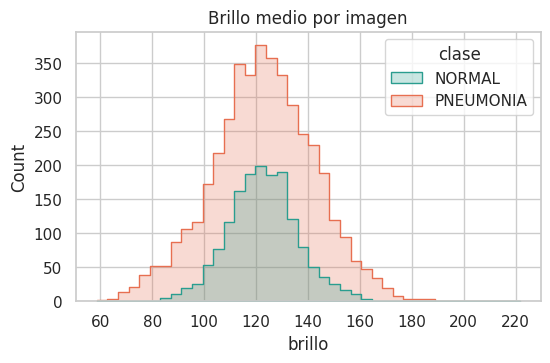

In [ ]:
def cargar(p): return np.asarray(Image.open(p).convert('L').resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8)
with ThreadPoolExecutor(8) as ex: imgs = list(tqdm(ex.map(cargar, data.path), total=len(data)))
X = np.stack(imgs)[..., None]; y = data.y.values
m_tr, m_va, m_te = [(data.particion == s).values for s in ['train','val','test']]
Xtr, ytr, Xva, yva, Xte, yte = X[m_tr], y[m_tr], X[m_va], y[m_va], X[m_te], y[m_te]
print('Formas:', Xtr.shape, Xva.shape, Xte.shape)

n0, n1 = (ytr==0).sum(), (ytr==1).sum()
CW = {0: len(ytr)/(2*n0), 1: len(ytr)/(2*n1)}
print('Pesos de clase:', {k: round(v,2) for k, v in CW.items()})

data['brillo'] = X.mean(axis=(1,2,3))
plt.figure(figsize=(6,3.5)); sns.histplot(data=data, x='brillo', hue='clase', bins=40, element='step', palette=['#2a9d8f','#e76f51'])
plt.title('Brillo medio por imagen'); guardar('A6_brillo')

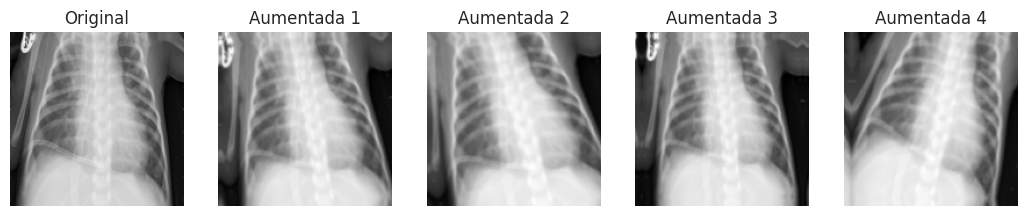

In [ ]:
def augment_layers():
    L = tf.keras.layers
    return tf.keras.Sequential([L.RandomRotation(0.05), L.RandomZoom(0.1),
                                L.RandomTranslation(0.05, 0.05), L.RandomContrast(0.1)], name='aumento')

idx = np.where(ytr == 1)[0][0]; img = Xtr[idx:idx+1].astype('float32') / 255
fig, axs = plt.subplots(1, 5, figsize=(13, 3))
axs[0].imshow(img[0,...,0], cmap='gray'); axs[0].set_title('Original')
aug_demo = augment_layers()
for k in range(1, 5):
    axs[k].imshow(aug_demo(img, training=True)[0,...,0], cmap='gray'); axs[k].set_title(f'Aumentada {k}')
for a in axs: a.axis('off')
guardar('A6_aumento_datos')

# Punto 5 – Modelo CNN
Arquitectura base (misma del baseline): bloques *Conv2D + MaxPooling* → *Flatten* → *Dense(128)* → *Dropout* → *Dense(1, sigmoide)*.
Los **hiperparámetros que se van a experimentar** son: aumento de datos, learning rate, dropout y número de bloques convolucionales (2 o 3, con 32/64/128 filtros).

In [ ]:
def build(aug, lr, dropout, bloques):
    L = tf.keras.layers
    capas = [L.Input((IMG, IMG, 1)), L.Rescaling(1/255)]
    if aug: capas.append(augment_layers())           # solo actúa en entrenamiento
    for i in range(bloques):
        capas += [L.Conv2D(32 * 2**i, 3, activation='relu'), L.MaxPooling2D(2)]
    capas += [L.Flatten(), L.Dense(128, activation='relu'), L.Dropout(dropout), L.Dense(1, activation='sigmoid')]
    m = tf.keras.Sequential(capas)
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.Recall(name='recall')])
    return m

build(True, 1e-3, 0.5, 3).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento (Sequential)            │ (None, 150, 150, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,827,905 (18.42 MB)

 Trainable params: 4,827,905 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

# Punto 6 – Protocolo experimental


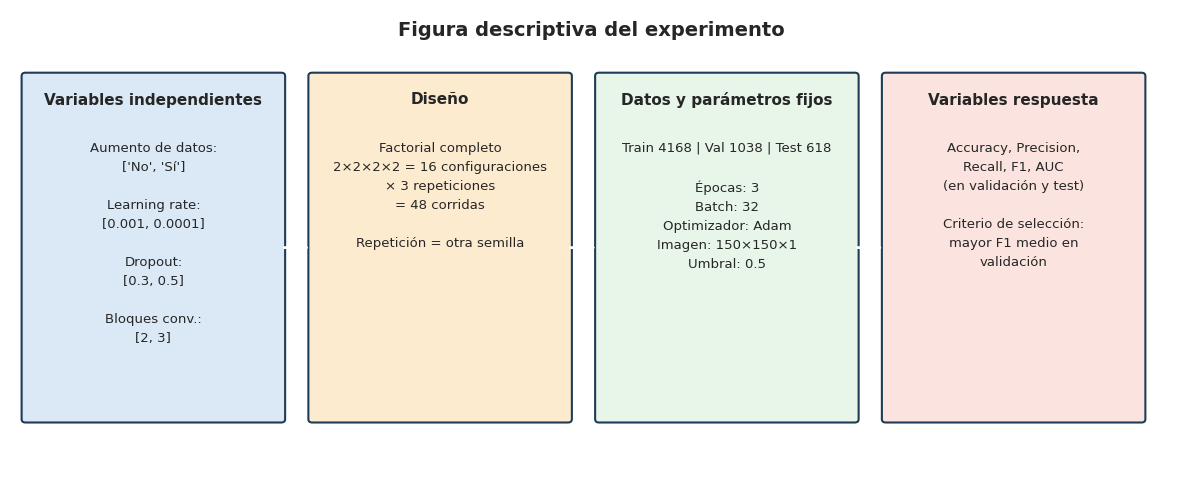

In [ ]:
FACTORES = {'aug': ['No','Sí'], 'lr': [1e-3, 1e-4], 'dropout': [0.3, 0.5], 'bloques': [2, 3]}
ETIQ = {'aug':'Aumento de datos','lr':'Learning rate','dropout':'Dropout','bloques':'Bloques conv.'}
CONFIGS = list(itertools.product(*FACTORES.values()))
FIJOS = {'Épocas': EPOCHS, 'Batch': BATCH, 'Optimizador': 'Adam', 'Imagen': '150×150×1', 'Umbral': 0.5}
N_RUNS = len(CONFIGS) * N_REPS

from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(15, 6)); ax.set_xlim(0, 15); ax.set_ylim(0, 7); ax.axis('off')
def caja(x, titulo, cuerpo, color, w=3.3):
    ax.add_patch(FancyBboxPatch((x, 0.8), w, 5.2, boxstyle='round,pad=0.05', fc=color, ec='#1f3b57', lw=1.5))
    ax.text(x + w/2, 5.75, titulo, ha='center', va='top', fontweight='bold', fontsize=11)
    ax.text(x + w/2, 5.0, cuerpo, ha='center', va='top', fontsize=9.5, linespacing=1.6)
def flecha(x): ax.annotate('', xy=(x+0.4, 3.4), xytext=(x, 3.4), arrowprops=dict(arrowstyle='->', lw=2))

caja(0.2, 'Variables independientes', '\n\n'.join(f'{ETIQ[k]}:\n{v}' for k, v in FACTORES.items()), '#dbe9f6')
caja(3.9, 'Diseño', f'Factorial completo\n2×2×2×2 = {len(CONFIGS)} configuraciones\n× {N_REPS} repeticiones\n= {N_RUNS} corridas\n\nRepetición = otra semilla', '#fdebd0')
caja(7.6, 'Datos y parámetros fijos', f'Train {len(ytr)} | Val {len(yva)} | Test {len(yte)}\n\n' + '\n'.join(f'{k}: {v}' for k, v in FIJOS.items()), '#e8f6e9')
caja(11.3, 'Variables respuesta', 'Accuracy, Precision,\nRecall, F1, AUC\n(en validación y test)\n\nCriterio de selección:\nmayor F1 medio en\nvalidación', '#fbe3e0')
for x in (3.5, 7.2, 10.9): flecha(x)
ax.text(7.5, 6.6, 'Figura descriptiva del experimento', ha='center', fontsize=14, fontweight='bold')
guardar('C_diseno_experimental')

## C.1 Ejecución del experimento
Para cada corrida: entrenar → evaluar en validación y test → guardar métricas.

In [ ]:
def ds(Xa, ya, train=False):
    d = tf.data.Dataset.from_tensor_slices((Xa, ya.astype('float32')))
    if train: d = d.shuffle(len(Xa), seed=SEED)
    return d.batch(BATCH).prefetch(tf.data.AUTOTUNE)
ds_tr, ds_va = ds(Xtr, ytr, True), ds(Xva, yva)

def metricas(m, Xa, ya):
    p = m.predict(Xa, batch_size=128, verbose=0).ravel(); yh = (p >= 0.5).astype(int)
    return dict(acc=accuracy_score(ya, yh), prec=precision_score(ya, yh, zero_division=0),
                recall=recall_score(ya, yh), f1=f1_score(ya, yh), auc=roc_auc_score(ya, p)), p

def entrenar(aug, lr, dropout, bloques, seed):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    m = build(aug == 'Sí', lr, dropout, bloques)
    h = m.fit(ds_tr, epochs=EPOCHS, validation_data=ds_va, class_weight=CW, verbose=0)
    return m, h

filas = []; t0 = time.time()
for (aug, lr, do, bl), rep in tqdm(list(itertools.product(CONFIGS, range(N_REPS))), desc='Corridas'):
    m, h = entrenar(aug, lr, do, bl, SEED + rep)
    mv, _ = metricas(m, Xva, yva); mt, _ = metricas(m, Xte, yte)
    filas.append(dict(aug=aug, lr=lr, dropout=do, bloques=bl, rep=rep,
                      **{f'val_{k}': v for k, v in mv.items()}, **{f'test_{k}': v for k, v in mt.items()}))
    pd.DataFrame(filas).to_csv('evidencias/resultados_crudos.csv', index=False)
print(f'Listo: {len(filas)} corridas en {(time.time()-t0)/60:.1f} min')

Corridas:   0%|          | 0/48 [00:00<?, ?it/s]

Listo: 48 corridas en 13.1 min


# Resultados y análisis
## D.1 Ranking de configuraciones
Tabla con media ± desviación (3 repeticiones). Se ordena por **F1 en validación**. Se incluye el **baseline** (la CNN original del notebook inicial) para comparar.

In [ ]:
res = pd.DataFrame(filas)
res['config'] = res.apply(lambda r: f'aug={r.aug} | lr={r.lr:g} | do={r.dropout} | bl={r.bloques}', axis=1)
BASELINE = 'aug=No | lr=0.001 | do=0.5 | bl=2'

cols = ['val_f1', 'val_recall', 'test_f1', 'test_recall', 'test_prec', 'test_acc', 'test_auc']
g = res.groupby('config')[cols].agg(['mean', 'std'])
orden = g[('val_f1', 'mean')].sort_values(ascending=False).index
tabla = pd.DataFrame({c: g[c]['mean'].round(3).astype(str) + ' ± ' + g[c]['std'].round(3).astype(str) for c in cols}).loc[orden]
tabla.insert(0, 'rank', range(1, len(tabla) + 1))
tabla.to_csv('evidencias/tabla_configuraciones.csv')

MEJOR = orden[0]
print('Top 5 configuraciones (por F1 en validación):'); display(tabla.head(5))
print('Baseline:'); display(tabla.loc[[BASELINE]])

Top 5 configuraciones (por F1 en validación):


,rank,val_f1,val_recall,test_f1,test_recall,test_prec,test_acc,test_auc
config,,,,,,,,
aug=No | lr=0.001 | do=0.3 | bl=2,1,0.977 ± 0.002,0.977 ± 0.005,0.843 ± 0.002,0.993 ± 0.004,0.732 ± 0.002,0.768 ± 0.002,0.908 ± 0.017
aug=No | lr=0.001 | do=0.3 | bl=3,2,0.973 ± 0.004,0.964 ± 0.004,0.862 ± 0.003,0.982 ± 0.005,0.768 ± 0.007,0.803 ± 0.006,0.925 ± 0.006
aug=No | lr=0.001 | do=0.5 | bl=2,3,0.972 ± 0.004,0.961 ± 0.015,0.855 ± 0.014,0.982 ± 0.007,0.758 ± 0.026,0.791 ± 0.024,0.919 ± 0.013
aug=No | lr=0.0001 | do=0.3 | bl=3,4,0.971 ± 0.002,0.974 ± 0.008,0.842 ± 0.006,0.99 ± 0.005,0.733 ± 0.011,0.768 ± 0.011,0.924 ± 0.004
aug=No | lr=0.001 | do=0.5 | bl=3,5,0.967 ± 0.008,0.959 ± 0.028,0.862 ± 0.023,0.984 ± 0.013,0.768 ± 0.043,0.802 ± 0.041,0.921 ± 0.017


Baseline:


,rank,val_f1,val_recall,test_f1,test_recall,test_prec,test_acc,test_auc
config,,,,,,,,
aug=No | lr=0.001 | do=0.5 | bl=2,3,0.972 ± 0.004,0.961 ± 0.015,0.855 ± 0.014,0.982 ± 0.007,0.758 ± 0.026,0.791 ± 0.024,0.919 ± 0.013


## D.2 Efecto de cada variable independiente
Promedio de F1 y Recall (validación) en cada nivel. Barras de error = desviación estándar.

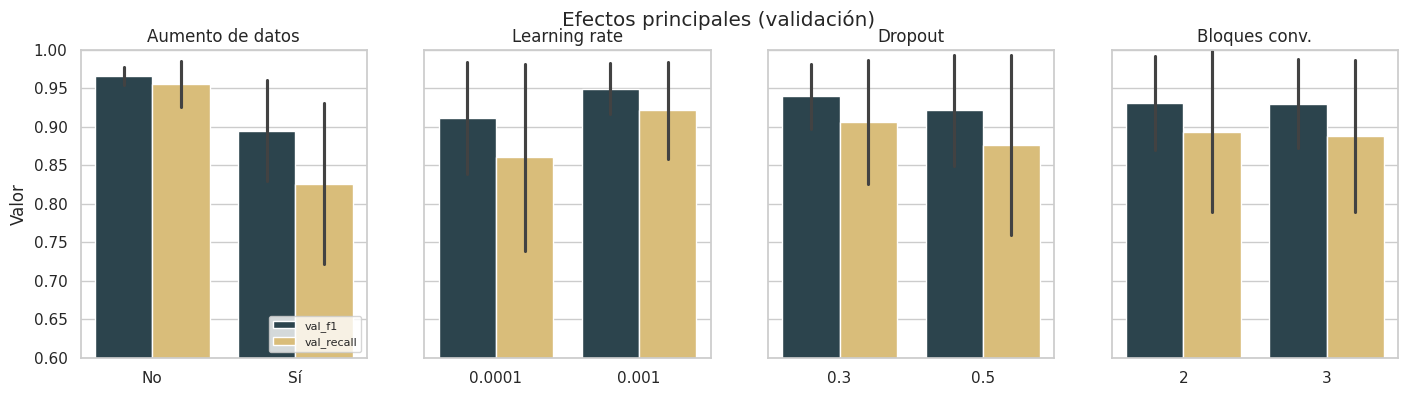

val_f1  val_recall  test_f1  test_recall
Aumento de datos No       0.966       0.956    0.859        0.979
                 Sí       0.895       0.826    0.870        0.863
Learning rate    0.0001   0.911       0.861    0.858        0.887
                 0.001    0.950       0.921    0.871        0.955
Dropout          0.3      0.940       0.906    0.870        0.936
                 0.5      0.921       0.876    0.860        0.906
Bloques conv.    2        0.931       0.894    0.861        0.920
                 3        0.930       0.888    0.868        0.922

In [ ]:
FACT = list(FACTORES)
fig, axs = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for ax, f in zip(axs, FACT):
    d = res.melt(id_vars=[f], value_vars=['val_f1', 'val_recall'], var_name='métrica', value_name='valor')
    sns.barplot(data=d, x=f, y='valor', hue='métrica', errorbar='sd', ax=ax, palette=['#264653', '#e9c46a'])
    ax.set_title(ETIQ[f]); ax.set_xlabel(''); ax.legend(loc='lower right', fontsize=8) if f == 'aug' else ax.legend_.remove()
axs[0].set_ylabel('Valor'); axs[0].set_ylim(0.6, 1.0)
plt.suptitle('Efectos principales (validación)'); guardar('D2_efectos_principales')

efectos = pd.concat({ETIQ[f]: res.groupby(f)[['val_f1','val_recall','test_f1','test_recall']].mean().round(3) for f in FACT})
display(efectos); efectos.to_csv('evidencias/tabla_efectos.csv')

## D.4 Generalización y compromiso Precision–Recall
Izquierda: ¿lo que se ve bueno en validación se mantiene en test? Derecha: Recall vs Precision por configuración (nos importa el **Recall** para evitar falsos negativos).

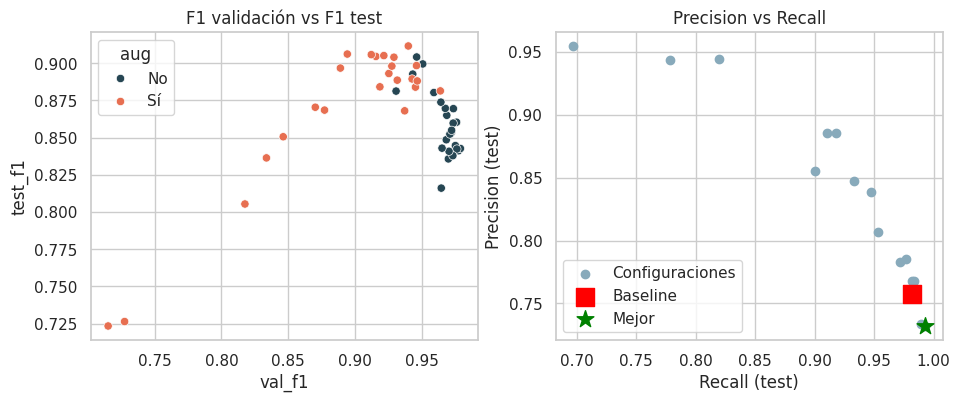

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=res, x='val_f1', y='test_f1', hue='aug', ax=axs[0], palette=['#264653', '#e76f51'])

# Se eliminó la línea: axs[0].plot([0.7, 1], [0.7, 1], 'k--', lw=1);
axs[0].set_title('F1 validación vs F1 test')

mc = res.groupby('config')[['test_prec', 'test_recall']].mean()
axs[1].scatter(mc.test_recall, mc.test_prec, c='#8ab', label='Configuraciones')
for nombre, col, mk in [(BASELINE, 'red', 's'), (MEJOR, 'green', '*')]:
    axs[1].scatter(mc.loc[nombre, 'test_recall'], mc.loc[nombre, 'test_prec'], c=col, marker=mk, s=160,
                   label='Baseline' if nombre == BASELINE else 'Mejor')
axs[1].set_xlabel('Recall (test)'); axs[1].set_ylabel('Precision (test)');
# Leyenda reubicada a la esquina inferior izquierda
axs[1].legend(loc='lower left');
axs[1].set_title('Precision vs Recall')
guardar('D4_generalizacion')

## D.5 Evaluación final de la mejor configuración
Se re-entrena la mejor configuración y se evalúa en test: curvas de aprendizaje, matriz de confusión y ROC.

Mejor configuración: aug=No | lr=0.001 | do=0.3 | bl=2


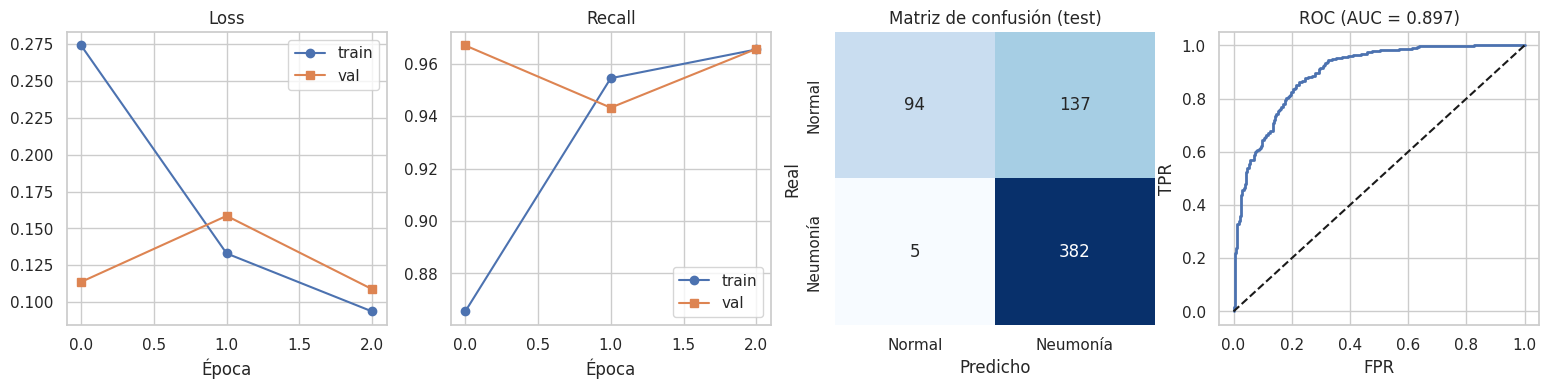

              precision    recall  f1-score   support

      Normal      0.949     0.407     0.570       231
    Neumonía      0.736     0.987     0.843       387

    accuracy                          0.770       618
   macro avg      0.843     0.697     0.706       618
weighted avg      0.816     0.770     0.741       618



In [ ]:
mejor = res[res.config == MEJOR].iloc[0]
mb, hb = entrenar(mejor.aug, float(mejor.lr), float(mejor.dropout), int(mejor.bloques), SEED)
mt, p = metricas(mb, Xte, yte); yh = (p >= 0.5).astype(int)
print('Mejor configuración:', MEJOR)

fig, axs = plt.subplots(1, 4, figsize=(19, 3.8))
for ax, k, t in [(axs[0], 'loss', 'Loss'), (axs[1], 'recall', 'Recall')]:
    ax.plot(hb.history[k], 'o-', label='train'); ax.plot(hb.history['val_' + k], 's-', label='val')
    ax.set_title(t); ax.set_xlabel('Época'); ax.legend()
sns.heatmap(confusion_matrix(yte, yh), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axs[2],
            xticklabels=['Normal', 'Neumonía'], yticklabels=['Normal', 'Neumonía'])
axs[2].set_title('Matriz de confusión (test)'); axs[2].set_xlabel('Predicho'); axs[2].set_ylabel('Real')
fpr, tpr, _ = roc_curve(yte, p); axs[3].plot(fpr, tpr, lw=2); axs[3].plot([0, 1], [0, 1], 'k--')
axs[3].set_title(f'ROC (AUC = {mt["auc"]:.3f})'); axs[3].set_xlabel('FPR'); axs[3].set_ylabel('TPR')
guardar('D5_evaluacion_mejor_modelo')
print(classification_report(yte, yh, target_names=['Normal', 'Neumonía'], digits=3))

Evaluando Modelo Baseline...


Evaluando Mejor Configuración...



--- MÉTRICAS EN EL CONJUNTO DE PRUEBA (TEST) ---
BASELINE (aug=No | lr=0.001 | do=0.5 | bl=2):
  F1: 0.854 | Recall: 0.979 | Precision: 0.756 | Exactitud: 0.790 | AUC: 0.904

MEJOR MODELO (aug=No | lr=0.001 | do=0.3 | bl=2):
  F1: 0.831 | Recall: 0.997 | Precision: 0.712 | Exactitud: 0.746 | AUC: 0.916

-> Mejora clínica en Recall: +0.018



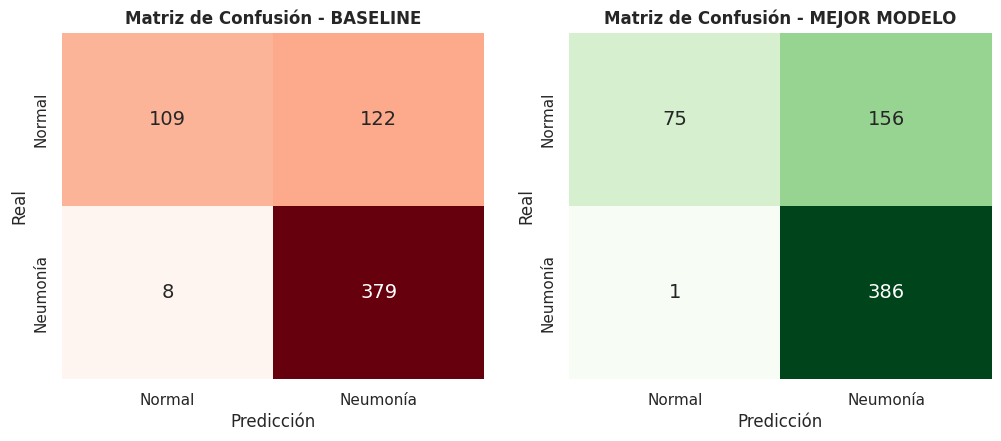

In [ ]:
# Obtener los hiperparámetros de ambas configuraciones
mejor = res[res.config == MEJOR].iloc[0]
baseline = res[res.config == BASELINE].iloc[0]

# Entrenar ambos modelos con la misma semilla para una comparación justa
print("Evaluando Modelo Baseline...")
m_base, _ = entrenar(baseline.aug, float(baseline.lr), float(baseline.dropout), int(baseline.bloques), SEED)
mt_base, p_base = metricas(m_base, Xte, yte)
yh_base = (p_base >= 0.5).astype(int)

print("Evaluando Mejor Configuración...")
m_mejor, _ = entrenar(mejor.aug, float(mejor.lr), float(mejor.dropout), int(mejor.bloques), SEED)
mt_mejor, p_mejor = metricas(m_mejor, Xte, yte)
yh_mejor = (p_mejor >= 0.5).astype(int)

# Imprimir las métricas comparativas
print('\n--- MÉTRICAS EN EL CONJUNTO DE PRUEBA (TEST) ---')
print(f'BASELINE ({BASELINE}):')
print(f'  F1: {mt_base["f1"]:.3f} | Recall: {mt_base["recall"]:.3f} | Precision: {mt_base["prec"]:.3f} | Exactitud: {mt_base["acc"]:.3f} | AUC: {mt_base["auc"]:.3f}')

print(f'\nMEJOR MODELO ({MEJOR}):')
print(f'  F1: {mt_mejor["f1"]:.3f} | Recall: {mt_mejor["recall"]:.3f} | Precision: {mt_mejor["prec"]:.3f} | Exactitud: {mt_mejor["acc"]:.3f} | AUC: {mt_mejor["auc"]:.3f}')

print(f'\n-> Mejora clínica en Recall: {mt_mejor["recall"] - mt_base["recall"]:+.3f}\n')

# Dibujar las matrices de confusión lado a lado
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(confusion_matrix(yte, yh_base), annot=True, fmt='d', cmap='Reds', cbar=False, ax=axs[0],
            xticklabels=['Normal', 'Neumonía'], yticklabels=['Normal', 'Neumonía'], annot_kws={"size": 14})
axs[0].set_title('Matriz de Confusión - BASELINE', fontsize=12, fontweight='bold')
axs[0].set_xlabel('Predicción')
axs[0].set_ylabel('Real')

sns.heatmap(confusion_matrix(yte, yh_mejor), annot=True, fmt='d', cmap='Greens', cbar=False, ax=axs[1],
            xticklabels=['Normal', 'Neumonía'], yticklabels=['Normal', 'Neumonía'], annot_kws={"size": 14})
axs[1].set_title('Matriz de Confusión - MEJOR MODELO', fontsize=12, fontweight='bold')
axs[1].set_xlabel('Predicción')
axs[1].set_ylabel('Real')

# Mostrar directamente en pantalla sin guardar nada
plt.show()